In [226]:
# Import libraries
import os
import pathlib
import pandas as pd
import numpy as np
import datetime as dt
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from collections import OrderedDict
import csv

from scipy.stats import ttest_ind, ttest_rel, ttest_1samp
from scipy.stats import chi2, chi2_contingency

%matplotlib inline

In [227]:
# Load and read file
data = pd.read_csv('StudentsPerformance.csv')
data.head() # Shows the head of the data 

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [228]:
data.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [229]:
# It shows the dimension of the data with number of records & attributes
data.shape

(1000, 8)

In [230]:
data.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [231]:
# To show the type of objects
data.dtypes

gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

In [232]:
data.dtypes.value_counts()

object    5
int64     3
dtype: int64

In [233]:
#to get statistical information
data.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [234]:
# To look for total number of missing values
data.isna().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [235]:
data.dropna()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


It is observed that no missing values are present.

# EXPLORATORY DATA  ANALYSIS 

Text(0, 0.5, 'math score')

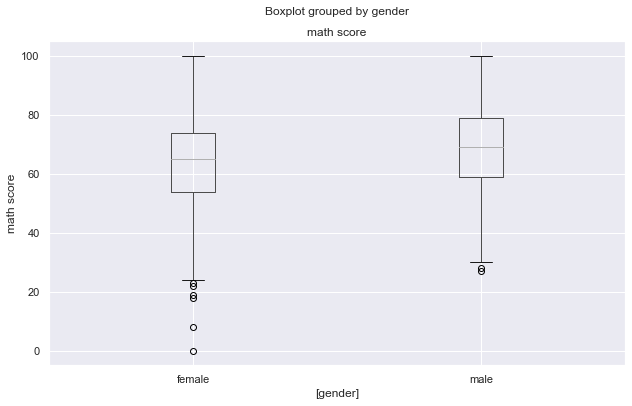

In [252]:
ax = data[['math score', 'gender']].boxplot(by='gender', figsize=(10,6))
ax.set_ylabel('math score')

Text(0.5, 0, 'math score')

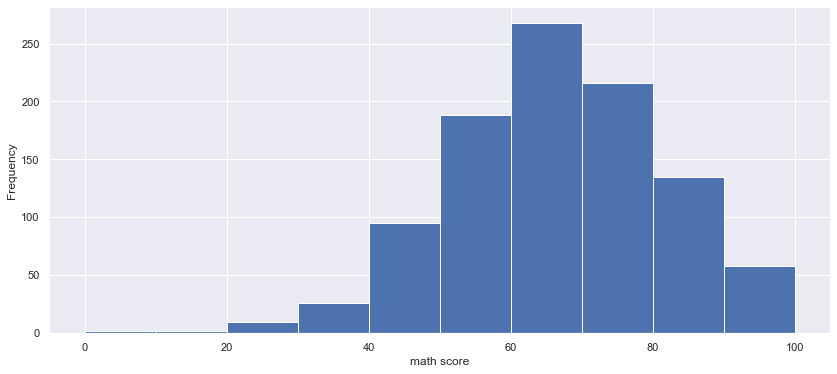

In [254]:
ax = data['math score'].plot(kind='hist', figsize=(14,6))
ax.set_xlabel('math score')

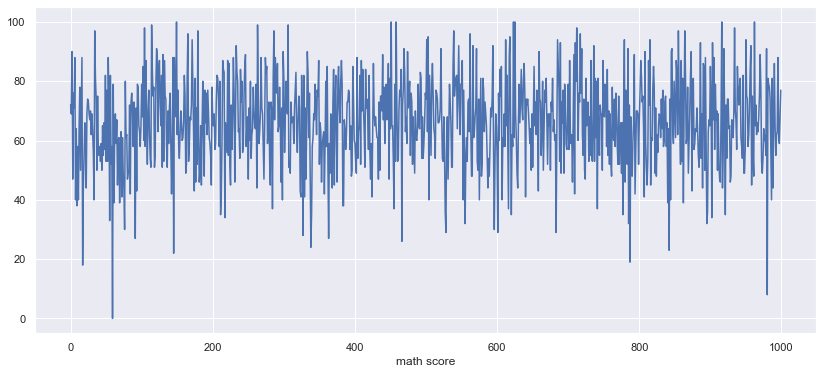

In [255]:
ax = data['math score'].plot(kind='line', figsize=(14,6))
plt.xlabel('math score')
plt.show()

<AxesSubplot:xlabel='gender', ylabel='count'>

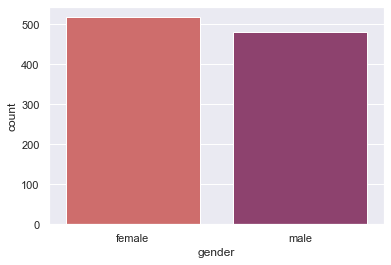

In [238]:
sns.countplot(x='gender', data= data, palette = 'flare')

The count of female is higher than male

<AxesSubplot:xlabel='parental level of education', ylabel='count'>

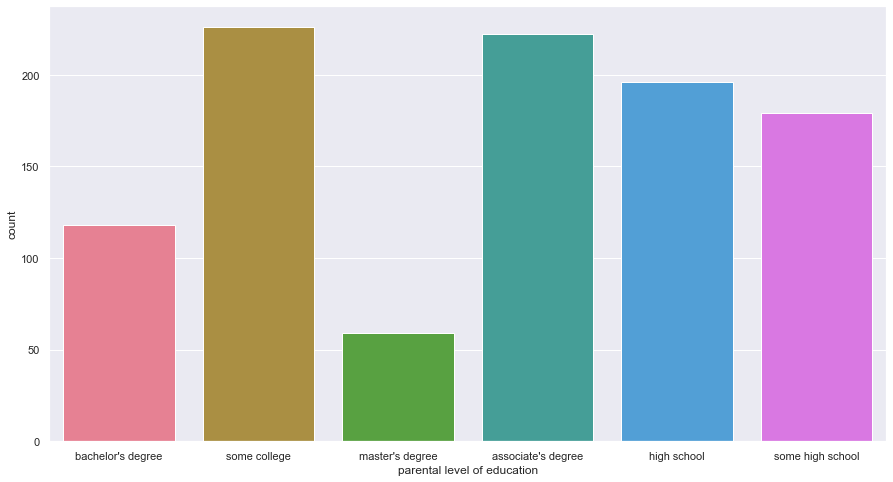

In [239]:
plt.figure(figsize = (15,8))
sns.countplot(x= 'parental level of education',data = data, palette = 'husl')


<AxesSubplot:xlabel='parental level of education', ylabel='count'>

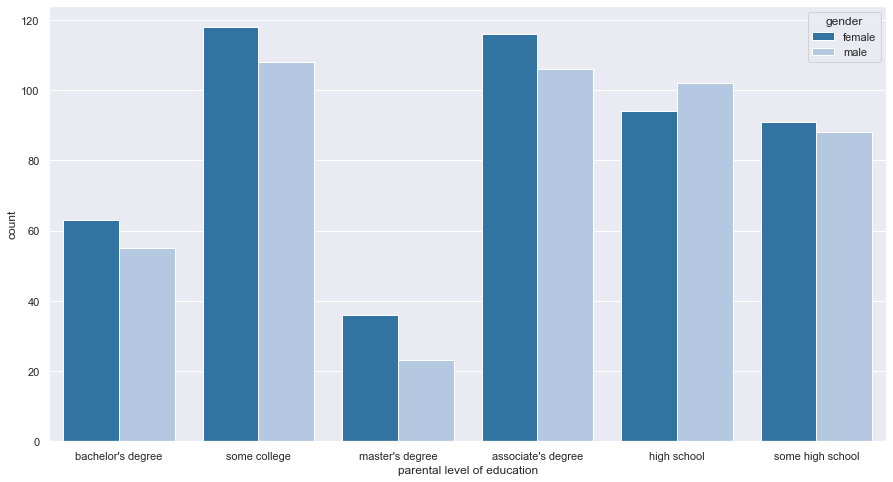

In [240]:
plt.figure(figsize = (15,8))
sns.countplot(x='parental level of education', data=data, hue='gender', palette = 'tab20')

The parental level of education from some college shows the highest count.

<AxesSubplot:xlabel='test preparation course', ylabel='count'>

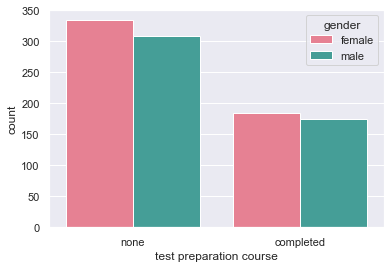

In [241]:
sns.countplot(x= 'test preparation course',data = data, hue = 'gender', palette = 'husl')

Both female and male did not complete test preparation course. More number of female did not complete the test preparation course than male.

<AxesSubplot:xlabel='race/ethnicity', ylabel='count'>

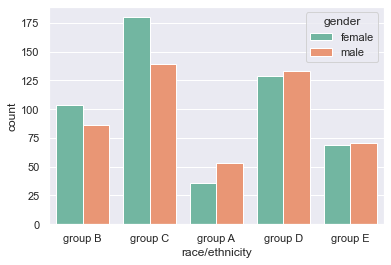

In [242]:
sns.countplot(x= 'race/ethnicity', data = data, hue = 'gender', palette ='Set2')

Group C has the highest race/ethnicity than the others while group A has the least number of race/ethnicity.

<AxesSubplot:ylabel='reading score'>

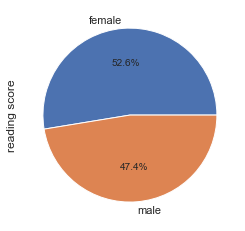

In [243]:
gender_data = data.groupby('gender')['reading score'].mean()
gender_data.plot.pie(autopct='%1.1f%%')

Female has the highest mean of reading score than male.

In [244]:
data['Average score'] = (data['math score']+data['reading score']+data['writing score'])/3
data['Average score']
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Average score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


<AxesSubplot:ylabel='Average score'>

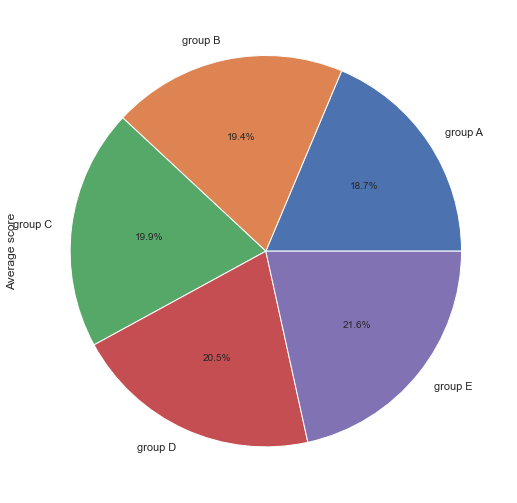

In [245]:
race = data.groupby('race/ethnicity')['Average score'].mean()
plt.figure(figsize = (10,9))
race.plot.pie(autopct='%1.1f%%')

# RELATIONSHIP BETWEEN COLUMNS

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2-D array with a single row if you intend to specify the same RGB or RGBA value for all points.


<AxesSubplot:xlabel='math score', ylabel='reading score'>

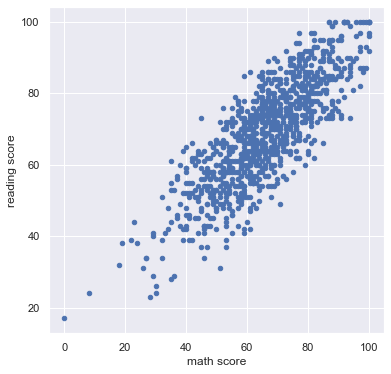

In [250]:
data.plot(kind='scatter', x ='math score', y= 'reading score', figsize=(6,6))

In [246]:
corr = data.corr()
corr

,math score,reading score,writing score,Average score
math score,1.000000,0.817580,0.802642,0.918746
reading score,0.817580,1.000000,0.954598,0.970331
writing score,0.802642,0.954598,1.000000,0.965667
Average score,0.918746,0.970331,0.965667,1.000000


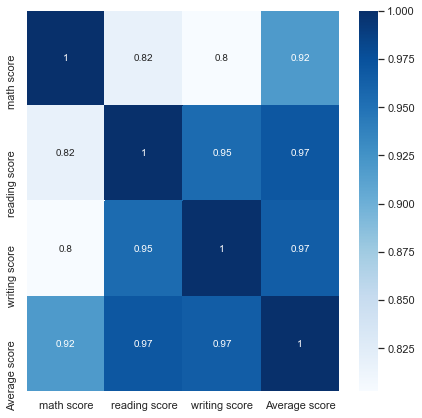

In [247]:
corr = data.corr()
plt.figure(figsize=(7,7))
sns.heatmap(corr, annot= True, cmap = 'Blues')
plt.show()

From the heat map, we can see that all the math score, reading score and writing score are positively correlated with each other.

In [248]:
data[(data['math score'] == 100) & (data['reading score']== 100) & (data['writing score']== 100)]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Average score
458,female,group E,bachelor's degree,standard,none,100,100,100,100.0
916,male,group E,bachelor's degree,standard,completed,100,100,100,100.0
962,female,group E,associate's degree,standard,none,100,100,100,100.0


From the table above, we can see that the students that obtained 100 in math score, reading score and writing score belongs to group E race/ethnicity. All their parents have either bachelor's degree or associate's degree. Two of the top scorers are female and one is male.

In [249]:
data_asc = data.sort_values(['math score', 'reading score', 'writing score'], ascending=False)
data_asc

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Average score
458,female,group E,bachelor's degree,standard,none,100,100,100,100.000000
916,male,group E,bachelor's degree,standard,completed,100,100,100,100.000000
962,female,group E,associate's degree,standard,none,100,100,100,100.000000
149,male,group E,associate's degree,free/reduced,completed,100,100,93,97.666667
625,male,group D,some college,standard,completed,100,97,99,98.666667
...,...,...,...,...,...,...,...,...,...
145,female,group C,some college,free/reduced,none,22,39,33,31.333333
787,female,group B,some college,standard,none,19,38,32,29.666667
17,female,group B,some high school,free/reduced,none,18,32,28,26.000000
980,female,group B,high school,free/reduced,none,8,24,23,18.333333


In [203]:
student_above_90 = data[(data['math score'] > 90) & (data['reading score']>90) & (data['writing score']>90)]
student_above_90

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Average score
114,female,group E,bachelor's degree,standard,completed,99,100,100,99.666667
149,male,group E,associate's degree,free/reduced,completed,100,100,93,97.666667
165,female,group C,bachelor's degree,standard,completed,96,100,100,98.666667
179,female,group D,some high school,standard,completed,97,100,100,99.000000
451,female,group E,some college,standard,none,100,92,97,96.333333
458,female,group E,bachelor's degree,standard,none,100,100,100,100.000000
546,female,group A,some high school,standard,completed,92,100,97,96.333333
566,female,group E,bachelor's degree,free/reduced,completed,92,100,100,97.333333
571,male,group A,bachelor's degree,standard,none,91,96,92,93.000000
594,female,group C,bachelor's degree,standard,completed,92,100,99,97.000000


<AxesSubplot:xlabel='gender', ylabel='count'>

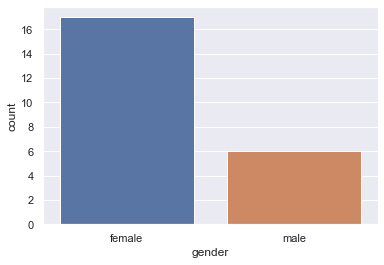

In [204]:
sns.countplot(x='gender', data=student_above_90)

In [205]:
student_above_90 = data[(data['math score'] < 30) & (data['reading score']< 30) & (data['writing score']< 30)]
student_above_90

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Average score
59,female,group C,some high school,free/reduced,none,0,17,10,9.000000
327,male,group A,some college,free/reduced,none,28,23,19,23.333333
980,female,group B,high school,free/reduced,none,8,24,23,18.333333


C:\Users\ghaya\anaconda3\lib\site-packages\seaborn\axisgrid.py:1969: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


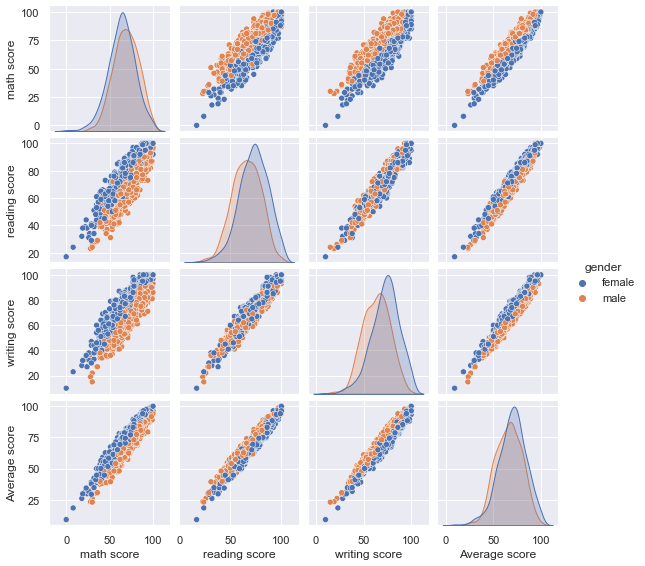

In [206]:
%matplotlib inline
import seaborn as sns; sns.set()
sns.pairplot(data,hue='gender',size=2.0);

# Min-max scaling

In [207]:
from sklearn.preprocessing import MinMaxScaler
X = np.array(data['Average score']).reshape(-1,1)
scaler = MinMaxScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)
data['min max'] = X_scaled.reshape(1,-1)[0]
data.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Average score,min max
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,0.699634
1,female,group C,some college,standard,completed,69,90,88,82.333333,0.805861
2,female,group B,master's degree,standard,none,90,95,93,92.666667,0.919414
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,0.443223
4,male,group C,some college,standard,none,76,78,75,76.333333,0.739927


# Dependent t-test

In [104]:
from scipy.stats import ttest_rel
a = data['math score']
b = data['reading score']
t, p = ttest_rel(a, b)
print('t-statistic: ', t)
print('p-value: ', p)
print('p-value is less than 0.05, reject null hypothesis')
print('Conclusion: There is a significant different in mean between math score and reading score')

t-statistic:  -10.816230631665421
p-value:  7.322335900414138e-26
p-value is less than 0.05, reject null hypothesis
Conclusion: There is a significant different in mean between math score and reading score


In [173]:
from scipy.stats import ttest_rel
a = data['math score']
b = data['reading score']
t, p = ttest_rel(a, b)
print('t-statistic: ', t)
print('p-value: ', p)

if p < 0.05:
  print(
      'p-value is less than 0.05, reject null hypothesis.'
      'There is a significant different in mean between math score and reading score.'
  )
else:
    print(
       'p-value is larger than 0.05, do not reject null hypothesis.'
       'There is no significant different in mean between math score and reading score'
  )

t-statistic:  -10.816230631665421
p-value:  7.322335900414138e-26
p-value is less than 0.05, reject null hypothesis.There is a significant different in mean between math score and reading score.


In [ ]:
stats.ttest_ind(train_data['reanalysis_dew_point_temp_k'][train_data['city'] == 'sj'],
                train_data['reanalysis_dew_point_temp_k'][train_data['city'] == 'iq'])

# Machine learning

In [208]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

In [209]:
#change the data types of categorial variables into integer
data = pd.get_dummies(data,columns=['gender','race/ethnicity','parental level of education','test preparation course','lunch'],dtype = int)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   math score                                      1000 non-null   int64  
 1   reading score                                   1000 non-null   int64  
 2   writing score                                   1000 non-null   int64  
 3   Average score                                   1000 non-null   float64
 4   min max                                         1000 non-null   float64
 5   gender_female                                   1000 non-null   int32  
 6   gender_male                                     1000 non-null   int32  
 7   race/ethnicity_group A                          1000 non-null   int32  
 8   race/ethnicity_group B                          1000 non-null   int32  
 9   race/ethnicity_group C                    

In [210]:
#Since gender does not seem to have a big impact on the score, let's remove the gender column
data.drop(['gender_female','gender_male'], axis=1)
#We are only concerned with the total score, so let's delete the math, reading and writing scores
data.drop(['math score','reading score','writing score'], axis=1)

,Average score,min max,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,test preparation course_completed,test preparation course_none,lunch_free/reduced,lunch_standard
0,72.666667,0.699634,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,1
1,82.333333,0.805861,1,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1
2,92.666667,0.919414,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1
3,49.333333,0.443223,0,1,1,0,0,0,0,1,0,0,0,0,0,0,1,1,0
4,76.333333,0.739927,0,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,94.000000,0.934066,1,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,1
996,57.333333,0.531136,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,1,0
997,65.000000,0.615385,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0
998,74.333333,0.717949,1,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,1


In [213]:
from scipy.stats import chi2_contingency 

# create contigency table for temperature vs windy
info = pd.crosstab(index=data['gender_male'], columns=data['race/ethnicity_group A'])

# perform chi square
print(info.values.tolist())
chi2, p, dof, _ = chi2_contingency(info.values.tolist())
print('chi2 value: ', chi2)
print('p value: ', p)
print('dof value: ', dof)

if p < 0.05:
  print(
      'Gender_male and race/ethnicity_group A are independent of each other.'
  )
else:
    print(
      'Gender_male and  race/ethnicity_group A are NOT independent of each other'
  )

[[482, 36], [429, 53]]
chi2 value:  4.5544739422269505
p value:  0.032832848527991905
dof value:  1
Gender_male and race/ethnicity_group A are independent of each other.


In [214]:
data.sample()

,math score,reading score,writing score,Average score,min max,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,...,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,test preparation course_completed,test preparation course_none,lunch_free/reduced,lunch_standard
884,51,51,54,52.0,0.472527,1,0,0,0,0,...,1,0,0,0,0,0,0,1,0,1


In [215]:
#split the data into train and test data
train_x,test_x,train_y,test_y = train_test_split(data.iloc[:,4:],data.iloc[:,3],test_size = 0.05)

In [165]:
test_x

,min max,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,test preparation course_completed,test preparation course_none,lunch_free/reduced,lunch_standard
616,0.340659,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,1
508,0.758242,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1
108,0.626374,1,0,0,1,0,0,0,1,0,0,0,0,0,0,1,1,0
115,0.761905,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1
200,0.769231,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1
542,0.769231,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,1
6,0.908425,1,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,1
458,1.000000,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,1
267,0.699634,1,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,1
28,0.652015,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1


In [166]:
#we will use the XGBoost ML model to train and predict
model = XGBRegressor(max_depth = 6)
model.fit(train_x,train_y)

XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, enable_categorical=False,
             gamma=0, gpu_id=-1, importance_type=None,
             interaction_constraints='', learning_rate=0.300000012,
             max_delta_step=0, max_depth=6, min_child_weight=1, missing=nan,
             monotone_constraints='()', n_estimators=100, n_jobs=8,
             num_parallel_tree=1, predictor='auto', random_state=0, reg_alpha=0,
             reg_lambda=1, scale_pos_weight=1, subsample=1, tree_method='exact',
             validate_parameters=1, verbosity=None)

In [167]:
#now we will set the target (actual value) and compared to the predicted value
target = model.predict(test_x)
mean_squared_error(target,test_y)

0.007506210496778486

In [168]:
#let's visualize the target size
len(target)

50

In [169]:
#let's visualize the values in the test data
test_y[:5].values

array([40.        , 78.        , 66.        , 78.33333333, 79.        ])

In [170]:
#let's visualize the values in the target data
target[:5]

array([40.35294, 77.98861, 65.98959, 78.34024, 78.98467], dtype=float32)